# ET on baseline.csv (Predict DX at M06)

In [ ]:
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl(lessexc).csv')

# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [ ]:
#### Hyperparameter Tuning

In [2]:
# Define the ExtraTrees classifier
clf = ExtraTreesClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 3, 4],
    'min_samples_leaf': [1, 2, 3],
    'bootstrap': [True, False]
}

In [3]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits


GridSearchCV(cv=5, estimator=ExtraTreesClassifier(), n_jobs=-1,
             param_grid={'bootstrap': [True, False], 'max_depth': [3, 4, 5],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [2, 3, 4],
                         'n_estimators': [100, 200, 300]},
             verbose=2)

In [4]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'bootstrap': False, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}


In [ ]:
### Model Training

In [5]:
# Train the ExtraTrees classifier with the best hyperparameters
clf = ExtraTreesClassifier(**best_params)
clf.fit(x_train, y_train)

ExtraTreesClassifier(max_depth=5, max_features='sqrt', n_estimators=300)

In [ ]:
### Model Testing

In [6]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [7]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.9738219895287958
Testing accuracy: 0.9634146341463414
Confusion matrix:
 [[ 47  11   0]
 [  0 163   1]
 [  0   0 106]]


In [8]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.81      0.90        58
           1       0.94      0.99      0.96       164
           2       0.99      1.00      1.00       106

    accuracy                           0.96       328
   macro avg       0.98      0.93      0.95       328
weighted avg       0.97      0.96      0.96       328



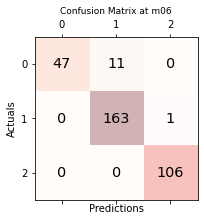

In [9]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Reds, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m06', fontsize=9)
plt.show()

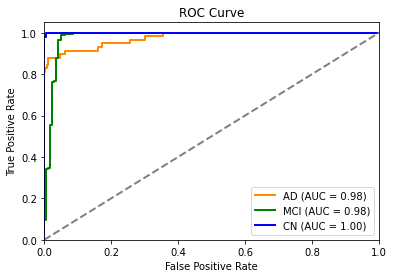

In [10]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()
plt.show()

# ET on bl&m06.csv (Predict DX at M12)

In [11]:
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06(lessexc).csv')

In [12]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [13]:
# Define the ExtraTrees classifier
clf = ExtraTreesClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 3, 4],
    'min_samples_leaf': [1, 2, 3],
    'bootstrap': [True, False]
}

In [14]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits


GridSearchCV(cv=5, estimator=ExtraTreesClassifier(), n_jobs=-1,
             param_grid={'bootstrap': [True, False], 'max_depth': [3, 4, 5],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [2, 3, 4],
                         'n_estimators': [100, 200, 300]},
             verbose=2)

In [15]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'bootstrap': False, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 300}


In [16]:
# Train the ExtraTrees classifier with the best hyperparameters
clf = ExtraTreesClassifier(**best_params)
clf.fit(x_train, y_train)

ExtraTreesClassifier(max_depth=5, max_features='sqrt', min_samples_leaf=2,
                     min_samples_split=4, n_estimators=300)

In [17]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [18]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.9581151832460733
Testing accuracy: 0.948170731707317
Confusion matrix:
 [[ 55  15   0]
 [  1 151   1]
 [  0   0 105]]


In [19]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.98      0.79      0.87        70
           1       0.91      0.99      0.95       153
           2       0.99      1.00      1.00       105

    accuracy                           0.95       328
   macro avg       0.96      0.92      0.94       328
weighted avg       0.95      0.95      0.95       328



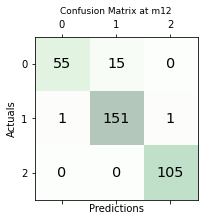

In [20]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Greens, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m12', fontsize=9)
plt.show()

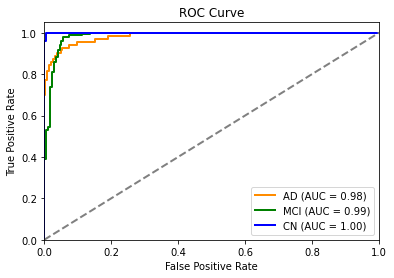

In [21]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# ET on bl&m06&m12.csv (Predict DX at M18) 

In [22]:
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12(lessexc).csv')

In [23]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [24]:
# Define the ExtraTrees classifier
clf = ExtraTreesClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 3, 4],
    'min_samples_leaf': [1, 2, 3],
    'bootstrap': [True, False]
}

In [25]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits


GridSearchCV(cv=5, estimator=ExtraTreesClassifier(), n_jobs=-1,
             param_grid={'bootstrap': [True, False], 'max_depth': [3, 4, 5],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [2, 3, 4],
                         'n_estimators': [100, 200, 300]},
             verbose=2)

In [26]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'bootstrap': True, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}


In [27]:
# Train the ExtraTrees classifier with the best hyperparameters
clf = ExtraTreesClassifier(**best_params)
clf.fit(x_train, y_train)

ExtraTreesClassifier(bootstrap=True, max_depth=5, max_features='sqrt',
                     min_samples_leaf=2, n_estimators=300)

In [28]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [29]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.975130890052356
Testing accuracy: 0.9603658536585366
Confusion matrix:
 [[ 70  13   0]
 [  0 140   0]
 [  0   0 105]]


In [30]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.84      0.92        83
           1       0.92      1.00      0.96       140
           2       1.00      1.00      1.00       105

    accuracy                           0.96       328
   macro avg       0.97      0.95      0.96       328
weighted avg       0.96      0.96      0.96       328



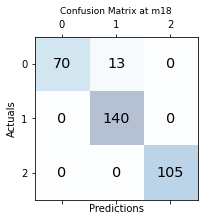

In [31]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m18', fontsize=9)
plt.show()

In [32]:
data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,DX,DX_m18
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,3234.0,0.629,2117.0,6979.0,2362.0,601.400000,251.700000,24.180000,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,3112.0,0.570,2175.0,905.0,1894.0,472.800000,334.100000,34.040000,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,2791.0,0.673,1713.0,737.0,2124.0,1064.913718,284.614621,27.130365,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2463.0,0.653,2093.0,1957.0,1758.0,1064.913718,284.614621,27.130365,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,2928.0,0.592,2087.0,681.0,1808.0,340.000000,287.700000,27.370000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,3186.0,0.728,2700.0,2115.0,2302.0,998.200000,472.000000,47.150000,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,2883.0,0.689,2375.0,2487.0,1481.0,1064.913718,284.614621,27.130365,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,3320.0,0.663,3072.0,129.0,2356.0,1087.000000,113.600000,9.020000,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,3957.0,0.574,2894.0,322.0,1683.0,1923.000000,228.600000,19.010000,1,1


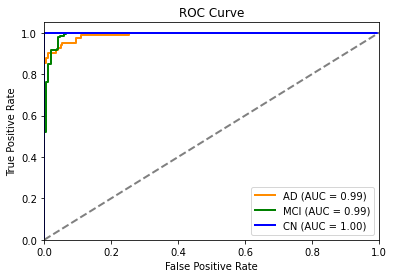

In [33]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# ET on bl&m06&m12&m18.csv (Predict DX at M24)

In [34]:
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12&m18(lessexc).csv')

In [35]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [36]:
# Define the ExtraTrees classifier
clf = ExtraTreesClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 3, 4],
    'min_samples_leaf': [1, 2, 3],
    'bootstrap': [True, False]
}

In [37]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits


GridSearchCV(cv=5, estimator=ExtraTreesClassifier(), n_jobs=-1,
             param_grid={'bootstrap': [True, False], 'max_depth': [3, 4, 5],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [2, 3, 4],
                         'n_estimators': [100, 200, 300]},
             verbose=2)

In [38]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'bootstrap': True, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 3, 'n_estimators': 100}


In [39]:
# Train the ExtraTrees classifier with the best hyperparameters
clf = ExtraTreesClassifier(**best_params)
clf.fit(x_train, y_train)

ExtraTreesClassifier(bootstrap=True, max_depth=5, max_features='sqrt',
                     min_samples_split=3)

In [40]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [41]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.943717277486911
Testing accuracy: 0.9207317073170732
Confusion matrix:
 [[ 86  21   0]
 [  1 115   4]
 [  0   0 101]]


In [42]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.99      0.80      0.89       107
           1       0.85      0.96      0.90       120
           2       0.96      1.00      0.98       101

    accuracy                           0.92       328
   macro avg       0.93      0.92      0.92       328
weighted avg       0.93      0.92      0.92       328



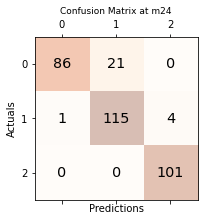

In [43]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Oranges, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m24', fontsize=9)
plt.show()

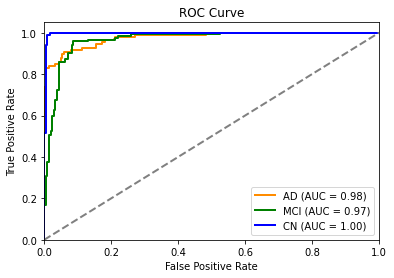

In [44]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

In [ ]:
confusion_matirx()